In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# --- GPU selection: use only ONE GPU (GPU 0) ---
# Option A (recommended): set CUDA_VISIBLE_DEVICES before CUDA is initialized.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed(0)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.cuda.set_device(0)
    torch.backends.cudnn.benchmark = True
    print("Using GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU")


Using GPU: Tesla T4


In [2]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

In [3]:
def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, total = 0.0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = F.cross_entropy(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * x.size(0)
        total += x.size(0)
    return total_loss / total

@torch.no_grad()
def eval_accuracy(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        pred = model(x).argmax(1)
        correct += (pred == y).sum().item()
        total += x.size(0)
    return correct / total

In [4]:
def clamp01(x):
    return torch.clamp(x, 0.0, 1.0)

@torch.no_grad()
def predict(model, x):
    model.eval()
    logits = model(x)
    return logits.argmax(dim=1)

def show_batch(images, labels=None, preds=None, n=8, title=None):
    images = images.detach().cpu()
    n = min(n, images.size(0))
    fig, axes = plt.subplots(1, n, figsize=(1.8*n, 2.0))
    if n == 1:
        axes = [axes]
    for i in range(n):
        axes[i].imshow(images[i,0], cmap="gray", vmin=0, vmax=1)
        axes[i].axis("off")
        t = []
        if labels is not None: t.append(f"y={int(labels[i])}")
        if preds is not None:  t.append(f"p={int(preds[i])}")
        axes[i].set_title("\n".join(t), fontsize=10)
    if title:
        fig.suptitle(title)
    plt.show()

def l_inf_norm(x_adv, x):
    # per-sample L_inf norm
    return (x_adv - x).abs().view(x.size(0), -1).max(dim=1).values


In [5]:
def fgsm_attack(model, x, y, eps, targeted=False, y_target=None):
    """
    Untargeted FGSM: maximize loss wrt true label y.
    Targeted FGSM:   minimize loss wrt target label y_target.
    """
    model.eval()
    x_adv = x.clone().detach().requires_grad_(True)

    model.train()
    logits = model(x_adv)

    if targeted:
        assert y_target is not None, "Provide y_target for targeted FGSM."
        loss = F.cross_entropy(logits, y_target)
        # targeted: gradient *descent* on loss => subtract sign(grad)
        grad_sign = torch.autograd.grad(loss, x_adv)[0].sign()
        x_adv = x_adv - eps * grad_sign
    else:
        loss = F.cross_entropy(logits, y)
        # untargeted: gradient *ascent* on loss => add sign(grad)
        grad_sign = torch.autograd.grad(loss, x_adv)[0].sign()
        x_adv = x_adv + eps * grad_sign

    x_adv = clamp01(x_adv.detach())
    return x_adv


In [6]:
def pgd_attack(model, x, y, eps, alpha, steps, random_start=True,
               targeted=False, y_target=None):
    """
    PGD in L_inf ball around x.
    Untargeted: maximize CE loss wrt y.
    Targeted:   minimize CE loss wrt y_target.
    """
    model.eval()

    x_orig = x.detach()
    if random_start:
        # uniform noise in [-eps, eps]
        x_adv = x_orig + (2*torch.rand_like(x_orig) - 1.0) * eps
        x_adv = clamp01(x_adv)
    else:
        x_adv = x_orig.clone()

    for _ in range(steps):
        x_adv = x_adv.clone().detach().requires_grad_(True)
        logits = model(x_adv)

        if targeted:
            assert y_target is not None, "Provide y_target for targeted PGD."
            loss = F.cross_entropy(logits, y_target)
            grad = torch.autograd.grad(loss, x_adv)[0]
            x_adv = x_adv - alpha * grad.sign()
        else:
            loss = F.cross_entropy(logits, y)
            grad = torch.autograd.grad(loss, x_adv)[0]
            x_adv = x_adv + alpha * grad.sign()

        # Project back to L_inf ball around x_orig
        delta = torch.clamp(x_adv - x_orig, min=-eps, max=eps)
        x_adv = clamp01(x_orig + delta)

    return x_adv.detach()


In [7]:
@torch.no_grad()
def eval_clean(model, loader):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        pred = model(x).argmax(1)
        correct += (pred == y).sum().item()
        total += x.size(0)
    return correct / total

def eval_under_attack(model, loader, attack_fn):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        x_adv = attack_fn(x, y)
        with torch.no_grad():
            pred = model(x_adv).argmax(1)
        correct += (pred == y).sum().item()
        total += x.size(0)
    return correct / total


In [8]:
import pandas as pd

def attack_suite(model, eps, pgd_steps_list=(10, 40)):
    """Return a dict of attack callables x,y -> x_adv for a given eps."""
    suite = {}
    suite["Clean"] = lambda x, y: x
    if eps > 0:
        suite[f"FGSM (eps={eps:.2f})"] = lambda x, y: fgsm_attack(model, x, y, eps=eps)
        for steps in pgd_steps_list:
            # A simple default step size; feel free to experiment
            alpha = eps / 4 if eps > 0 else 0.0
            suite[f"PGD-{steps} (eps={eps:.2f})"] = lambda x, y, a=alpha, s=steps: pgd_attack(
                model, x, y, eps=eps, alpha=a, steps=s, random_start=True
            )
    return suite

def eval_attack_accuracy(model, loader, attack_fn):
    model.eval()
    correct, total = 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        x_adv = attack_fn(x, y)
        with torch.no_grad():
            pred = model(x_adv).argmax(1)
        correct += (pred == y).sum().item()
        total += x.size(0)
    return correct / total

def sweep_attacks(model, loader, eps_list, pgd_steps_list=(10, 40), max_batches=None):
    """Return a DataFrame with accuracy for multiple attacks across eps values.
    4 types of attacks, clean, FGSM, PGD-10 and PGD-40"""
    rows = []
    for eps in eps_list:
        suite = attack_suite(model, eps, pgd_steps_list=pgd_steps_list)
        for name, fn in suite.items():
            # Optionally evaluate only on a subset of batches for speed
            if max_batches is None:
                acc = eval_attack_accuracy(model, loader, fn)
            else:
                model.eval()
                correct, total = 0, 0
                for bi, (x, y) in enumerate(loader):
                    if bi >= max_batches:
                        break
                    x, y = x.to(device), y.to(device)
                    x_adv = fn(x, y)
                    with torch.no_grad():
                        pred = model(x_adv).argmax(1)
                    correct += (pred == y).sum().item()
                    total += x.size(0)
                acc = correct / total
            rows.append({"epsilon": float(eps), "attack": name.split(" (eps=")[0], "accuracy": acc})
    df = pd.DataFrame(rows)
    return df


In [9]:
def train_one_epoch_adv_fgsm(model, loader, optimizer, eps, lam=0.5):
    """
    Simple adversarial training:
    loss = (1-lam)*CE(clean) + lam*CE(adv)
    where adv is generated using FGSM on the current model.
    """
    model.train()
    total_loss, total = 0.0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        # --- generate adversarial examples (using current model) ---
        # We generate x_adv in "eval-style" but gradients wrt x are required.
        x_adv = fgsm_attack(model, x, y, eps=eps, targeted=False)
        model.train()

        # --- compute mixed loss and update parameters ---
        optimizer.zero_grad()
        logits_clean = model(x)
        logits_adv   = model(x_adv)

        loss_clean = F.cross_entropy(logits_clean, y)
        loss_adv   = F.cross_entropy(logits_adv, y)

        loss = (1 - lam) * loss_clean + lam * loss_adv
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        total += x.size(0)

    return total_loss / total


In [10]:
def train_one_epoch_adv_pgd(model, loader, optimizer, eps, alpha=None, steps=7,
                            lam=0.5, random_start=True):
    """
    Adversarial training with PGD:
    loss = (1-lam)*CE(clean) + lam*CE(adv)
    where adv is generated with PGD (L_inf) on the current model.
    """
    # Regla habitual: alpha ~ 2.5*eps/steps para poder alcanzar el borde de la bola
    if alpha is None:
        alpha = 2.5 * eps / steps

    total_loss, total = 0.0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        # --- generate adversarial examples (using current model) ---
        # pgd_attack pone model.eval() internamente, así que lo restauramos después
        x_adv = pgd_attack(model, x, y, eps=eps, alpha=alpha, steps=steps,
                           random_start=random_start, targeted=False)
        model.train()

        # --- compute mixed loss and update parameters ---
        optimizer.zero_grad()
        logits_clean = model(x)
        logits_adv   = model(x_adv)

        loss_clean = F.cross_entropy(logits_clean, y)
        loss_adv   = F.cross_entropy(logits_adv, y)

        loss = (1 - lam) * loss_clean + lam * loss_adv
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        total += x.size(0)

    return total_loss / total

In [11]:
@torch.no_grad()
def get_probs_labels(model, loader, attack_fn=None, max_batches=None):
    """Devuelve probabilidades softmax y etiquetas, opcionalmente bajo ataque."""
    model.eval()
    all_probs, all_labels = [], []
    for bi, (x, y) in enumerate(loader):
        if max_batches is not None and bi >= max_batches:
            break
        x, y = x.to(device), y.to(device)
        if attack_fn is not None:
            with torch.enable_grad():          # el ataque necesita gradientes
                x = attack_fn(x, y)
        probs = F.softmax(model(x), dim=1)
        all_probs.append(probs.cpu())
        all_labels.append(y.cpu())
    return torch.cat(all_probs), torch.cat(all_labels)

def compute_ece(probs, labels, n_bins=15):
    conf, pred = probs.max(dim=1)
    correct = (pred == labels).float()
    bins = torch.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        if mask.any():
            ece += mask.float().mean() * (correct[mask].mean() - conf[mask].mean()).abs()
    return float(ece)

def compute_nll(probs, labels):
    return float(F.nll_loss(torch.log(probs.clamp_min(1e-12)), labels))

def reliability_diagram(probs, labels, n_bins=15, title=""):
    conf, pred = probs.max(dim=1)
    correct = (pred == labels).float()
    bins = torch.linspace(0, 1, n_bins + 1)
    accs, centers = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (conf > lo) & (conf <= hi)
        accs.append(correct[mask].mean().item() if mask.any() else 0.0)
        centers.append(((lo + hi) / 2).item())
    plt.figure(figsize=(4.5, 4.5))
    plt.bar(centers, accs, width=1/n_bins, edgecolor="k", alpha=0.7, label="Accuracy")
    plt.plot([0, 1], [0, 1], "r--", label="Perfect calibration")
    plt.xlabel("Confidence"); plt.ylabel("Accuracy")
    plt.title(f"{title}\nECE={compute_ece(probs, labels, n_bins):.3f}")
    plt.legend(); plt.show()

def calibration_sweep(model, loader, eps_list, name):
    rows = []
    for eps in eps_list:
        attacks = {"Clean": None}
        if eps > 0:
            attacks["FGSM"] = lambda x, y, e=eps: fgsm_attack(model, x, y, eps=e)
            attacks["PGD-10"] = lambda x, y, e=eps: pgd_attack(model, x, y, eps=e, alpha=e/4, steps=10)
        for atk_name, fn in attacks.items():
            p, l = get_probs_labels(model, loader, fn)
            rows.append({"training": name, "epsilon": eps, "attack": atk_name,
                         "acc": (p.argmax(1) == l).float().mean().item(),
                         "ECE": compute_ece(p, l), "NLL": compute_nll(p, l)})
    return pd.DataFrame(rows)

In [16]:
from torch.utils.data import DataLoader, Subset
from google.colab import drive
drive.mount("/content/drive")

DATA_DIR = "/content/drive/MyDrive/datasets"

batch_size = 128

# CIFAR-10 in [0,1]
cifar_transform = transforms.Compose([transforms.ToTensor()])

cifar_train_ds = datasets.CIFAR10(root=DATA_DIR, train=True, download=True, transform=cifar_transform)
cifar_test_ds  = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=cifar_transform)

# Usamos Subset para limitar el dataset de forma correcta
# cifar_train_subset = Subset(cifar_train_ds, range(5000))
# cifar_test_subset  = Subset(cifar_test_ds, range(5000))
cifar_train_subset = cifar_train_ds
cifar_test_subset  = cifar_test_ds

# DataLoader stability: use num_workers=0 (safe on macOS / Python 3.12)
cifar_train_loader = DataLoader(cifar_train_subset, batch_size=batch_size, shuffle=True, num_workers=0, pin_memory=torch.cuda.is_available())
cifar_test_loader  = DataLoader(cifar_test_subset,  batch_size=batch_size, shuffle=False, num_workers=0, pin_memory=torch.cuda.is_available())

cifar_classes = cifar_train_ds.classes
cifar_classes

Mounted at /content/drive


['airplane',
 'automobile',
 'bird',
 'cat',
 'deer',
 'dog',
 'frog',
 'horse',
 'ship',
 'truck']

In [ ]:
class SmallCIFARCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, 3, padding=1)
        self.conv2 = nn.Conv2d(64, 128, 3, padding=1)
        self.conv3 = nn.Conv2d(128, 128, 3, padding=1)
        self.conv4 = nn.Conv2d(128, 256, 3, padding=1)
        self.fc1   = nn.Linear(256 * 2 * 2, 256)
        self.fc2   = nn.Linear(256, num_classes)

    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = F.max_pool2d(x, 2)   # 32 -> 16
        x = F.relu(self.conv2(x))
        x = F.max_pool2d(x, 2)   # 16 -> 8
        x = F.relu(self.conv3(x))
        x = F.max_pool2d(x, 2)   # 8 -> 4
        x = F.relu(self.conv4(x))
        x = F.max_pool2d(x, 2)   # 4 -> 2
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

cifar_model = SmallCIFARCNN().to(device)
cifar_opt = torch.optim.Adam(cifar_model.parameters(), lr=1e-3)

In [ ]:
# Train a few epochs (increase epochs for better accuracy)
cifar_epochs = 5
for epoch in range(cifar_epochs):
    loss = train_one_epoch(cifar_model, cifar_train_loader, cifar_opt)
    acc = eval_clean(cifar_model, cifar_test_loader)
    print(f"[CIFAR-10 clean] epoch={epoch+1} loss={loss:.4f} test_acc={acc*100:.2f}%")

[CIFAR-10 clean] epoch=1 loss=1.6026 test_acc=52.43%
[CIFAR-10 clean] epoch=2 loss=1.1463 test_acc=57.99%
[CIFAR-10 clean] epoch=3 loss=0.9271 test_acc=68.77%
[CIFAR-10 clean] epoch=4 loss=0.7710 test_acc=70.01%
[CIFAR-10 clean] epoch=5 loss=0.6584 test_acc=72.69%


attack,Clean,FGSM,PGD-10,PGD-40
epsilon,,,,
0.000000,0.727,nan,nan,nan
0.001961,0.727,0.640,0.636,0.636
0.003922,0.727,0.556,0.543,0.540
0.007843,0.727,0.413,0.368,0.356
0.015686,0.727,0.217,0.132,0.114
0.031373,0.727,0.062,0.010,0.006


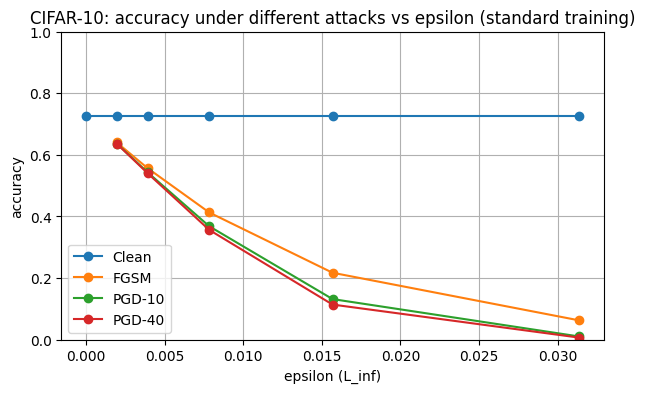

In [ ]:
# Sweep attacks for the CIFAR-10 clean-trained model
cifar_eps_list = [0.0, 0.5/255, 1/255, 2/255, 4/255, 8/255]  # common CIFAR scales, different attack intensities
df_cifar_std = sweep_attacks(cifar_model, cifar_test_loader, cifar_eps_list, pgd_steps_list=(10, 40), max_batches=128)
df_cifar_std["training"] = "Standard"

table_cifar_std = df_cifar_std.pivot_table(index="epsilon", columns="attack", values="accuracy")
display(table_cifar_std.style.format("{:.3f}"))

plt.figure(figsize=(7,4))
for col in table_cifar_std.columns:
    plt.plot(table_cifar_std.index, table_cifar_std[col], marker="o", label=col)
plt.xlabel("epsilon (L_inf)")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.grid(True)
plt.legend()
plt.title("CIFAR-10: accuracy under different attacks vs epsilon (standard training)")
plt.show()


In [ ]:
# FGSM
cifar_adv_model = SmallCIFARCNN().to(device)
cifar_adv_opt = torch.optim.Adam(cifar_adv_model.parameters(), lr=1e-3)

cifar_adv_eps = 8/255   # typical training budget on CIFAR-10 (perturbation)
cifar_lam = 0.5 # weight of the adversarial loss (loss = (1 - 0.5) · CE(clean) + 0.5 · CE(adv))
cifar_adv_epochs = 5

for epoch in range(cifar_adv_epochs):
    loss = train_one_epoch_adv_fgsm(cifar_adv_model, cifar_train_loader, cifar_adv_opt, eps=cifar_adv_eps, lam=cifar_lam)
    acc = eval_clean(cifar_adv_model, cifar_test_loader)
    print(f"[CIFAR-10 adv-train] epoch={epoch+1} loss={loss:.4f} clean_test_acc={acc*100:.2f}%")

[CIFAR-10 adv-train] epoch=1 loss=1.9021 clean_test_acc=47.43%
[CIFAR-10 adv-train] epoch=2 loss=1.6432 clean_test_acc=55.41%
[CIFAR-10 adv-train] epoch=3 loss=1.5315 clean_test_acc=57.85%
[CIFAR-10 adv-train] epoch=4 loss=1.4483 clean_test_acc=62.35%
[CIFAR-10 adv-train] epoch=5 loss=1.3853 clean_test_acc=64.33%


Does FGSM-based AT improve robustness against:

FGSM?

PGD?

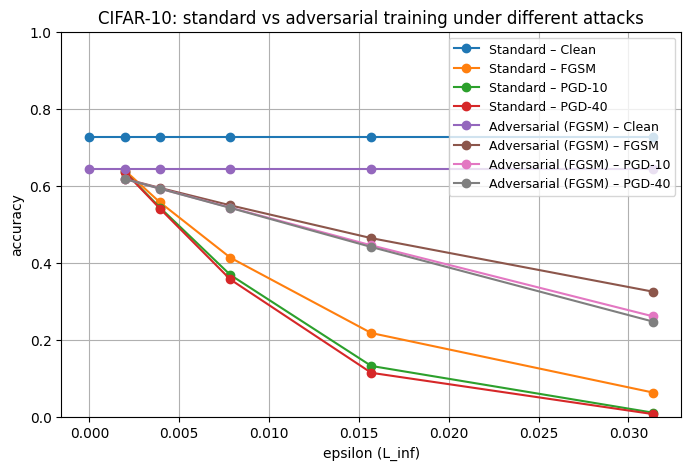

In [ ]:
df_cifar_adv = sweep_attacks(cifar_adv_model, cifar_test_loader, cifar_eps_list, pgd_steps_list=(10, 40), max_batches=128)
df_cifar_adv["training"] = "Adversarial (FGSM)"

df_cifar_all = pd.concat([df_cifar_std, df_cifar_adv], ignore_index=True)

table_cifar = df_cifar_all.pivot_table(index=["training", "epsilon"], columns="attack", values="accuracy")
display(table_cifar.style.format("{:.3f}"))

plt.figure(figsize=(8,5))
for training in df_cifar_all["training"].unique():
    sub = df_cifar_all[df_cifar_all["training"] == training]
    for attack in sub["attack"].unique():
        sub2 = sub[sub["attack"] == attack].sort_values("epsilon")
        plt.plot(sub2["epsilon"], sub2["accuracy"], marker="o", label=f"{training} – {attack}")

plt.xlabel("epsilon (L_inf)")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.grid(True)
plt.legend(fontsize=9)
plt.title("CIFAR-10: standard vs adversarial training under different attacks")
plt.show()

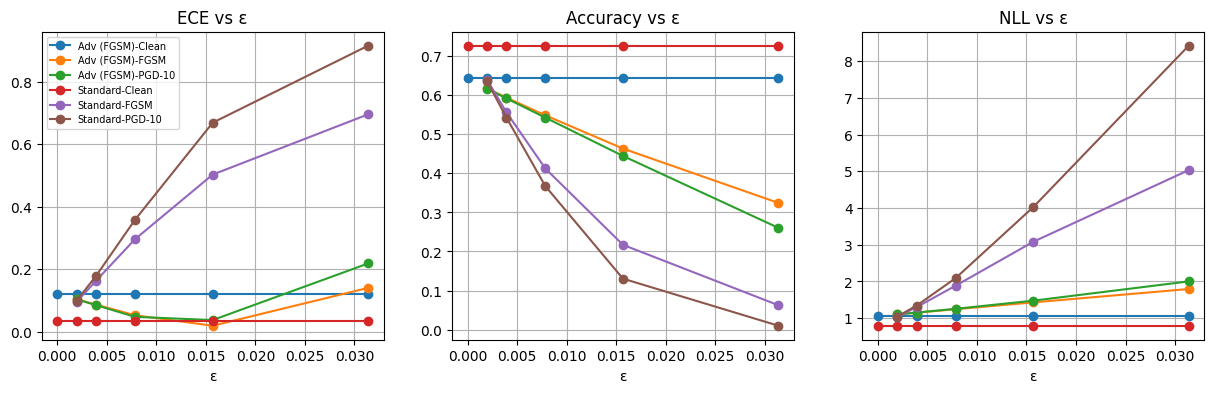

In [ ]:
df_cal = pd.concat([calibration_sweep(cifar_model, cifar_test_loader, cifar_eps_list, "Standard"),
                    calibration_sweep(cifar_adv_model, cifar_test_loader, cifar_eps_list, "Adv (FGSM)")])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for (tr, atk), g in df_cal.groupby(["training", "attack"]):
    g = g.sort_values("epsilon")
    axes[0].plot(g["epsilon"], g["ECE"], marker="o", label=f"{tr}-{atk}")
    axes[1].plot(g["epsilon"], g["acc"], marker="o", label=f"{tr}-{atk}")
    axes[2].plot(g["epsilon"], g["NLL"], marker="o", label=f"{tr}-{atk}")
for ax, t in zip(axes, ["ECE vs ε", "Accuracy vs ε", "NLL vs ε"]):
    ax.set_title(t); ax.set_xlabel("ε"); ax.grid(True)
axes[0].legend(fontsize=7); plt.show()

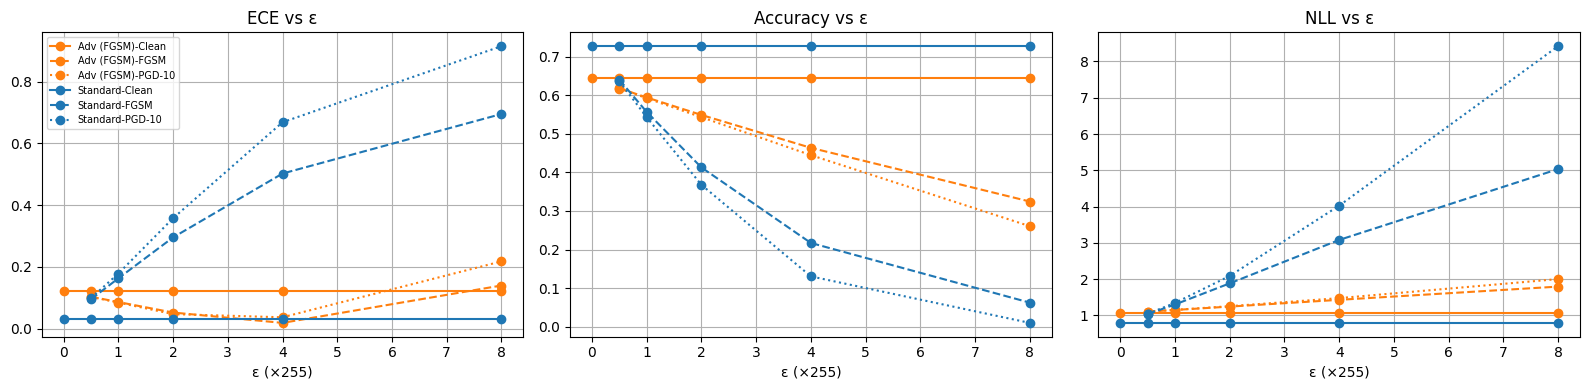

In [ ]:
# Alternative format with the same results as above
styles = {"Clean": "-", "FGSM": "--", "PGD-10": ":"}
colors = {"Standard": "tab:blue", "Adv (FGSM)": "tab:orange"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))   # <-- crear la figura aquí

for (tr, atk), g in df_cal.groupby(["training", "attack"]):
    g = g.sort_values("epsilon")
    for ax, m in zip(axes, ["ECE", "acc", "NLL"]):
        ax.plot(g["epsilon"] * 255, g[m], marker="o",
                color=colors[tr], ls=styles[atk], label=f"{tr}-{atk}")
for ax, t in zip(axes, ["ECE vs ε", "Accuracy vs ε", "NLL vs ε"]):
    ax.set_title(t); ax.set_xlabel("ε (×255)"); ax.grid(True)

axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()


In [ ]:
train_eps_list = [1/255, 2/255, 4/255, 8/255]
adv_models = {}

for eps_tr in train_eps_list:
    set_seed(0)
    m = SmallCIFARCNN().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for epoch in range(cifar_adv_epochs):
        train_one_epoch_adv_fgsm(m, cifar_train_loader, opt, eps=eps_tr, lam=1.0)
    adv_models[eps_tr] = m
    print(f"trained adv model eps={eps_tr*255:.0f}/255")

# Each model is evaluated with attacks to its own training ε
rows = []

# Standard baseline (ε=0)
p, l = get_probs_labels(cifar_model, cifar_test_loader)
rows.append({"train_eps": 0.0, "clean_acc": (p.argmax(1)==l).float().mean().item(),
             "ECE": compute_ece(p, l), "NLL": compute_nll(p, l)})

for eps_tr, m in adv_models.items():
    p, l = get_probs_labels(m, cifar_test_loader)
    row = {"train_eps": eps_tr, "clean_acc": (p.argmax(1)==l).float().mean().item(),
           "ECE": compute_ece(p, l), "NLL": compute_nll(p, l)}
    for name, fn in {"FGSM": lambda x,y,e=eps_tr,mm=m: fgsm_attack(mm,x,y,eps=e),
                     "PGD": lambda x,y,e=eps_tr,mm=m: pgd_attack(mm,x,y,eps=e,alpha=e/4,steps=10)}.items():
        pa, la = get_probs_labels(m, cifar_test_loader, fn)
        row[f"{name}_acc"] = (pa.argmax(1)==la).float().mean().item()
        row[f"{name}_ECE"] = compute_ece(pa, la)
    rows.append(row)

df_train_eps = pd.DataFrame(rows)

trained adv model eps=1/255
trained adv model eps=2/255
trained adv model eps=4/255
trained adv model eps=8/255


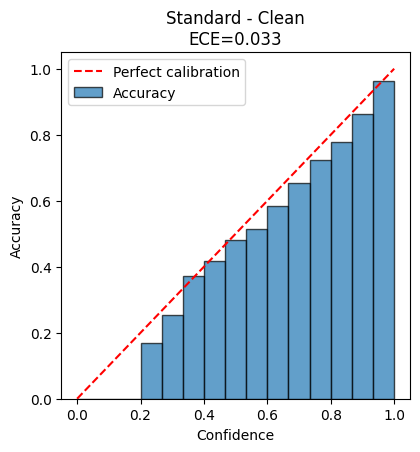

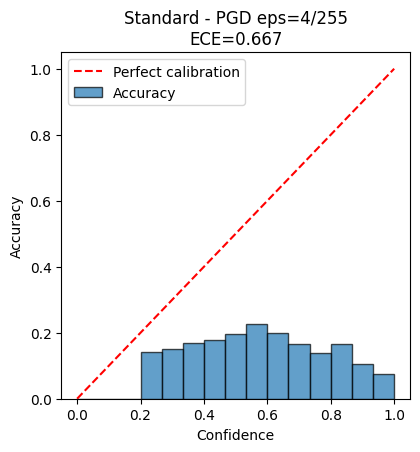

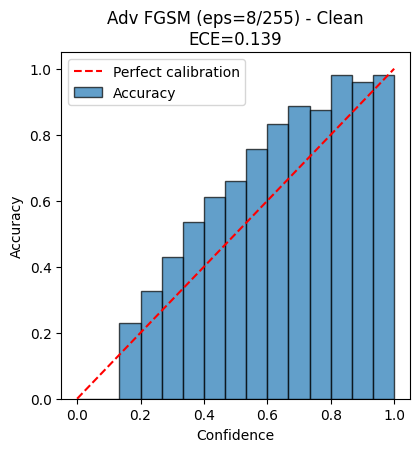

In [ ]:
p, l = get_probs_labels(cifar_model, cifar_test_loader)
reliability_diagram(p, l, title="Standard - Clean")

eps = 4/255
p, l = get_probs_labels(cifar_model, cifar_test_loader,
                        lambda x,y: pgd_attack(cifar_model,x,y,eps=eps,alpha=eps/4,steps=10))
reliability_diagram(p, l, title="Standard - PGD eps=4/255")

m = adv_models[8/255]
p, l = get_probs_labels(m, cifar_test_loader)
reliability_diagram(p, l, title="Adv FGSM (eps=8/255) - Clean")

In [ ]:
def calib_stats(p, l, n_bins=15):
    conf, pred = p.max(1)
    acc = (pred == l).float().mean().item()
    return dict(acc=acc, ECE=compute_ece(p, l, n_bins), NLL=compute_nll(p, l),
                conf=conf.mean().item(), gap=conf.mean().item() - acc)  # gap>0: sobreconfiado

models = {"Standard": cifar_model,
          **{f"AT-FGSM {round(e*255)}/255": m for e, m in adv_models.items()}}
test_eps = [1/255, 2/255, 4/255, 8/255]

rows = []
for name, m in models.items():
    p, l = get_probs_labels(m, cifar_test_loader)
    rows.append(dict(model=name, attack="Clean", eps=0.0, **calib_stats(p, l)))
    for e in test_eps:
        atks = {
            "FGSM":   lambda x, y, m=m, e=e: fgsm_attack(m, x, y, eps=e),
            "PGD-10": lambda x, y, m=m, e=e: pgd_attack(m, x, y, eps=e, alpha=e/4, steps=10),
        }
        for an, fn in atks.items():
            p, l = get_probs_labels(m, cifar_test_loader, fn)
            rows.append(dict(model=name, attack=an, eps=e, **calib_stats(p, l)))

df = pd.DataFrame(rows)
df["eps255"] = df["eps"] * 255

Does FGSM-based AT improve robustness against:
FGSM?
PGD?

In [ ]:
for atk in ["FGSM", "PGD-10"]:
    print(atk)
    display(df[df.attack == atk].pivot(index="eps255", columns="model", values="acc").style.format("{:.3f}"))

FGSM


model,AT-FGSM 1/255,AT-FGSM 2/255,AT-FGSM 4/255,AT-FGSM 8/255,Standard
eps255,,,,,
1.000000,0.629,0.609,0.561,0.507,0.557
2.000000,0.538,0.544,0.521,0.481,0.413
4.000000,0.382,0.429,0.444,0.430,0.217
8.000000,0.177,0.242,0.311,0.341,0.062


PGD-10


model,AT-FGSM 1/255,AT-FGSM 2/255,AT-FGSM 4/255,AT-FGSM 8/255,Standard
eps255,,,,,
1.000000,0.625,0.607,0.560,0.507,0.543
2.000000,0.521,0.535,0.517,0.479,0.368
4.000000,0.324,0.396,0.429,0.422,0.130
8.000000,0.082,0.158,0.258,0.314,0.010


Does increased robustness correlate with better or worse calibration?

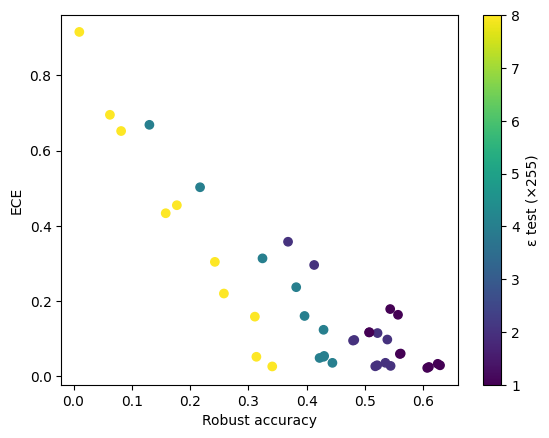

         acc       ECE       NLL
acc  1.00000 -0.740150 -0.983490
ECE -0.74015  1.000000  0.809568
NLL -0.98349  0.809568  1.000000


In [ ]:
atk_df = df[df.attack != "Clean"]
plt.scatter(atk_df["acc"], atk_df["ECE"], c=atk_df["eps255"], cmap="viridis")
plt.colorbar(label="ε test (×255)"); plt.xlabel("Robust accuracy"); plt.ylabel("ECE"); plt.show()

print(atk_df[["acc", "ECE", "NLL"]].corr(method="spearman"))

Are adversarially trained models overconfident or underconfident?

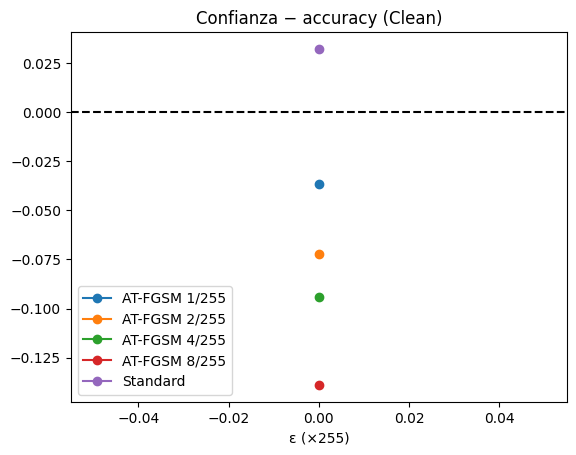

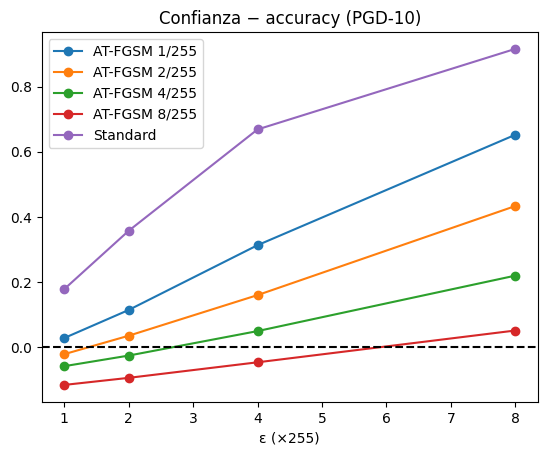

In [ ]:
for atk in ["Clean", "PGD-10"]:
    sub = df[df.attack == atk]
    for name, g in sub.groupby("model"):
        plt.plot(g["eps255"], g["gap"], marker="o", label=name)
    plt.axhline(0, color="k", ls="--"); plt.title(f"Confianza − accuracy ({atk})")
    plt.xlabel("ε (×255)"); plt.legend(); plt.show()

How do calibration metrics evolve as ε increases?

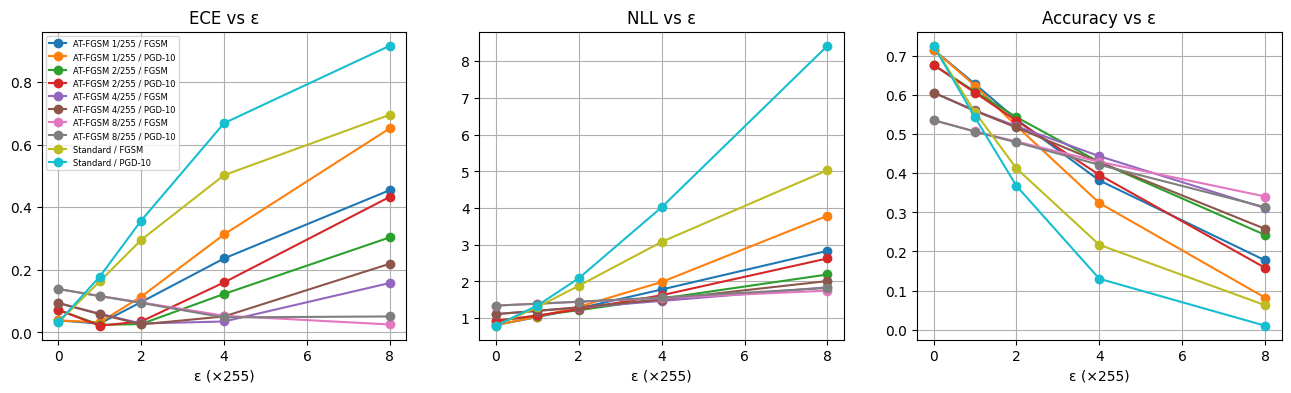

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (name, atk), g in df[df.attack.isin(["Clean", "FGSM", "PGD-10"])].groupby(["model", "attack"]):
    if atk == "Clean":
        continue
    g = pd.concat([df[(df.model == name) & (df.attack == "Clean")], g]).sort_values("eps255")
    for ax, metric in zip(axes, ["ECE", "NLL", "acc"]):
        ax.plot(g["eps255"], g[metric], marker="o", label=f"{name} / {atk}")
for ax, t in zip(axes, ["ECE vs ε", "NLL vs ε", "Accuracy vs ε"]):
    ax.set_title(t); ax.set_xlabel("ε (×255)"); ax.grid(True)
axes[0].legend(fontsize=6); plt.show()

# Resnet-18

In [12]:
from torchvision.models import resnet18, ResNet18_Weights

In [13]:
class ResNet(nn.Module):
    def __init__(self, pretrained=True, cifar_stem=True):
        super().__init__()
        weights = ResNet18_Weights.DEFAULT if pretrained else None
        resnet = resnet18(weights=weights)
        if cifar_stem:
            resnet.conv1 = nn.Conv2d(3, 64, 3, stride=1, padding=1, bias=False)
            resnet.maxpool = nn.Identity()
        self.in_features = resnet.fc.in_features
        self.backbone = nn.Sequential(*list(resnet.children())[:-1])

    def forward(self, x):
        return torch.flatten(self.backbone(x), 1)

In [14]:
class ResNet18Classifier(nn.Module):
    def __init__(self, num_classes=10, pretrained=True):
        super().__init__()
        self.backbone = ResNet(pretrained=pretrained)
        self.fc = nn.Linear(self.backbone.in_features, num_classes)
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        x = (x - self.mean) / self.std
        return self.fc(self.backbone(x))

In [17]:
cifar_resnet_model = ResNet18Classifier().to(device)
cifar_resnet_opt = torch.optim.Adam(cifar_resnet_model.parameters(), lr=1e-3)

cifar_resnet_epochs = 15
for epoch in range(cifar_resnet_epochs):
    loss = train_one_epoch(cifar_resnet_model, cifar_train_loader, cifar_resnet_opt)
    acc = eval_clean(cifar_resnet_model, cifar_test_loader)
    print(f"[ResNet standard] epoch={epoch+1} loss={loss:.4f} test_acc={acc*100:.2f}%")

[ResNet standard] epoch=1 loss=0.7089 test_acc=83.19%
[ResNet standard] epoch=2 loss=0.3674 test_acc=86.29%
[ResNet standard] epoch=3 loss=0.2377 test_acc=84.08%
[ResNet standard] epoch=4 loss=0.1670 test_acc=84.88%
[ResNet standard] epoch=5 loss=0.1176 test_acc=87.41%
[ResNet standard] epoch=6 loss=0.0928 test_acc=85.89%
[ResNet standard] epoch=7 loss=0.0775 test_acc=86.99%
[ResNet standard] epoch=8 loss=0.0637 test_acc=88.00%
[ResNet standard] epoch=9 loss=0.0602 test_acc=86.53%
[ResNet standard] epoch=10 loss=0.0499 test_acc=87.26%
[ResNet standard] epoch=11 loss=0.0450 test_acc=87.74%
[ResNet standard] epoch=12 loss=0.0457 test_acc=88.84%
[ResNet standard] epoch=13 loss=0.0369 test_acc=87.15%
[ResNet standard] epoch=14 loss=0.0380 test_acc=87.17%
[ResNet standard] epoch=15 loss=0.0380 test_acc=88.04%


attack,Clean,FGSM,PGD-10,PGD-40
epsilon,,,,
0.000000,0.880,nan,nan,nan
0.001961,0.880,0.765,0.627,0.620
0.003922,0.881,0.717,0.316,0.288
0.007843,0.880,0.603,0.049,0.030
0.015686,0.880,0.445,0.001,0.000
0.031373,0.878,0.337,0.000,0.000


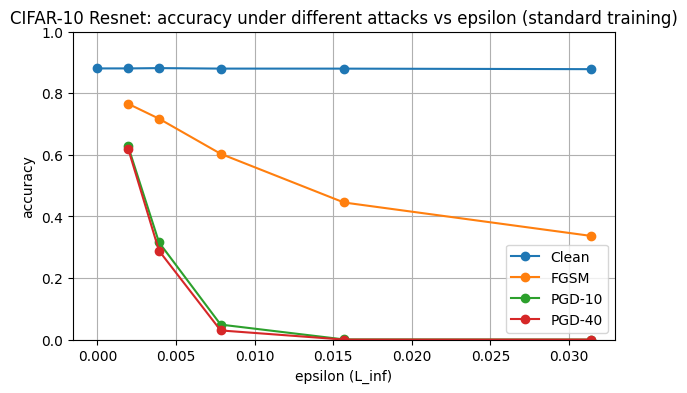

In [18]:
# Sweep attacks for the CIFAR-10 clean-trained model
cifar_eps_list = [0.0, 0.5/255, 1/255, 2/255, 4/255, 8/255]  # common CIFAR scales, different attack intensities
df_cifar_std = sweep_attacks(cifar_resnet_model, cifar_test_loader, cifar_eps_list, pgd_steps_list=(10, 40), max_batches=128)
df_cifar_std["training"] = "Standard"

table_cifar_std = df_cifar_std.pivot_table(index="epsilon", columns="attack", values="accuracy")
display(table_cifar_std.style.format("{:.3f}"))

plt.figure(figsize=(7,4))
for col in table_cifar_std.columns:
    plt.plot(table_cifar_std.index, table_cifar_std[col], marker="o", label=col)
plt.xlabel("epsilon (L_inf)")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.grid(True)
plt.legend()
plt.title("CIFAR-10 Resnet: accuracy under different attacks vs epsilon (standard training)")
plt.show()


In [20]:
# FGSM
cifar_resnet_adv_model = ResNet18Classifier().to(device)
cifar_resnet_adv_opt = torch.optim.Adam(cifar_resnet_adv_model.parameters(), lr=1e-3)

cifar_adv_eps = 8/255   # typical training budget on CIFAR-10 (perturbation)
cifar_lam = 0.5 # weight of the adversarial loss (loss = (1 - 0.5) · CE(clean) + 0.5 · CE(adv))
cifar_adv_epochs = 5

for epoch in range(cifar_adv_epochs):
    loss = train_one_epoch_adv_fgsm(cifar_resnet_adv_model, cifar_train_loader, cifar_resnet_adv_opt, eps=cifar_adv_eps, lam=cifar_lam)
    acc = eval_clean(cifar_resnet_adv_model, cifar_test_loader)
    print(f"[CIFAR-10 adv-train] epoch={epoch+1} loss={loss:.4f} clean_test_acc={acc*100:.2f}%")

[CIFAR-10 adv-train] epoch=1 loss=1.2381 clean_test_acc=72.66%
[CIFAR-10 adv-train] epoch=2 loss=0.7054 clean_test_acc=77.03%
[CIFAR-10 adv-train] epoch=3 loss=0.5066 clean_test_acc=81.01%
[CIFAR-10 adv-train] epoch=4 loss=0.3457 clean_test_acc=80.26%
[CIFAR-10 adv-train] epoch=5 loss=0.2169 clean_test_acc=81.31%


Does FGSM-based AT improve robustness against:

FGSM?

PGD?

In [ ]:
df_cifar_resnet_adv = sweep_attacks(cifar_resnet_adv_model, cifar_test_loader, cifar_eps_list, pgd_steps_list=(10, 40), max_batches=128)
df_cifar_resnet_adv["training"] = "Adversarial (FGSM)"

df_cifar_all = pd.concat([df_cifar_std, df_cifar_adv], ignore_index=True)

table_cifar = df_cifar_all.pivot_table(index=["training", "epsilon"], columns="attack", values="accuracy")
display(table_cifar.style.format("{:.3f}"))

plt.figure(figsize=(8,5))
for training in df_cifar_all["training"].unique():
    sub = df_cifar_all[df_cifar_all["training"] == training]
    for attack in sub["attack"].unique():
        sub2 = sub[sub["attack"] == attack].sort_values("epsilon")
        plt.plot(sub2["epsilon"], sub2["accuracy"], marker="o", label=f"{training} – {attack}")

plt.xlabel("epsilon (L_inf)")
plt.ylabel("accuracy")
plt.ylim(0, 1.0)
plt.grid(True)
plt.legend(fontsize=9)
plt.title("CIFAR-10: standard vs adversarial training under different attacks")
plt.show()

In [ ]:
df_cal = pd.concat([calibration_sweep(cifar_resnet_model, cifar_test_loader, cifar_eps_list, "Standard"),
                    calibration_sweep(cifar_resnet_adv_model, cifar_test_loader, cifar_eps_list, "Adv (FGSM)")])

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for (tr, atk), g in df_cal.groupby(["training", "attack"]):
    g = g.sort_values("epsilon")
    axes[0].plot(g["epsilon"], g["ECE"], marker="o", label=f"{tr}-{atk}")
    axes[1].plot(g["epsilon"], g["acc"], marker="o", label=f"{tr}-{atk}")
    axes[2].plot(g["epsilon"], g["NLL"], marker="o", label=f"{tr}-{atk}")
for ax, t in zip(axes, ["ECE vs ε", "Accuracy vs ε", "NLL vs ε"]):
    ax.set_title(t); ax.set_xlabel("ε"); ax.grid(True)
axes[0].legend(fontsize=7); plt.show()

In [ ]:
# Alternative format with the same results as above
styles = {"Clean": "-", "FGSM": "--", "PGD-10": ":"}
colors = {"Standard": "tab:blue", "Adv (FGSM)": "tab:orange"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))   # <-- crear la figura aquí

for (tr, atk), g in df_cal.groupby(["training", "attack"]):
    g = g.sort_values("epsilon")
    for ax, m in zip(axes, ["ECE", "acc", "NLL"]):
        ax.plot(g["epsilon"] * 255, g[m], marker="o",
                color=colors[tr], ls=styles[atk], label=f"{tr}-{atk}")
for ax, t in zip(axes, ["ECE vs ε", "Accuracy vs ε", "NLL vs ε"]):
    ax.set_title(t); ax.set_xlabel("ε (×255)"); ax.grid(True)

axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()


In [ ]:
train_eps_list = [1/255, 2/255, 4/255, 8/255]
adv_models = {}

for eps_tr in train_eps_list:
    set_seed(0)
    m = ResNet18Classifier().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for epoch in range(cifar_adv_epochs):
        train_one_epoch_adv_fgsm(m, cifar_train_loader, opt, eps=eps_tr, lam=1.0)
    adv_models[eps_tr] = m
    print(f"trained adv model eps={eps_tr*255:.0f}/255")

# Each model is evaluated with attacks to its own training ε
rows = []

# Standard baseline (ε=0)
p, l = get_probs_labels(cifar_resnet_model, cifar_test_loader)
rows.append({"train_eps": 0.0, "clean_acc": (p.argmax(1)==l).float().mean().item(),
             "ECE": compute_ece(p, l), "NLL": compute_nll(p, l)})

for eps_tr, m in adv_models.items():
    p, l = get_probs_labels(m, cifar_test_loader)
    row = {"train_eps": eps_tr, "clean_acc": (p.argmax(1)==l).float().mean().item(),
           "ECE": compute_ece(p, l), "NLL": compute_nll(p, l)}
    for name, fn in {"FGSM": lambda x,y,e=eps_tr,mm=m: fgsm_attack(mm,x,y,eps=e),
                     "PGD": lambda x,y,e=eps_tr,mm=m: pgd_attack(mm,x,y,eps=e,alpha=e/4,steps=10)}.items():
        pa, la = get_probs_labels(m, cifar_test_loader, fn)
        row[f"{name}_acc"] = (pa.argmax(1)==la).float().mean().item()
        row[f"{name}_ECE"] = compute_ece(pa, la)
    rows.append(row)

df_train_eps = pd.DataFrame(rows)

In [ ]:
p, l = get_probs_labels(cifar_model, cifar_test_loader)
reliability_diagram(p, l, title="Standard - Clean")

eps = 4/255
p, l = get_probs_labels(cifar_model, cifar_test_loader,
                        lambda x,y: pgd_attack(cifar_model,x,y,eps=eps,alpha=eps/4,steps=10))
reliability_diagram(p, l, title="Standard - PGD eps=4/255")

m = adv_models[8/255]
p, l = get_probs_labels(m, cifar_test_loader)
reliability_diagram(p, l, title="Adv FGSM (eps=8/255) - Clean")

In [ ]:
def calib_stats(p, l, n_bins=15):
    conf, pred = p.max(1)
    acc = (pred == l).float().mean().item()
    return dict(acc=acc, ECE=compute_ece(p, l, n_bins), NLL=compute_nll(p, l),
                conf=conf.mean().item(), gap=conf.mean().item() - acc)  # gap>0: sobreconfiado

models = {"Standard": cifar_resnet_model,
          **{f"AT-FGSM {round(e*255)}/255": m for e, m in adv_models.items()}}
test_eps = [1/255, 2/255, 4/255, 8/255]

rows = []
for name, m in models.items():
    p, l = get_probs_labels(m, cifar_test_loader)
    rows.append(dict(model=name, attack="Clean", eps=0.0, **calib_stats(p, l)))
    for e in test_eps:
        atks = {
            "FGSM":   lambda x, y, m=m, e=e: fgsm_attack(m, x, y, eps=e),
            "PGD-10": lambda x, y, m=m, e=e: pgd_attack(m, x, y, eps=e, alpha=e/4, steps=10),
        }
        for an, fn in atks.items():
            p, l = get_probs_labels(m, cifar_test_loader, fn)
            rows.append(dict(model=name, attack=an, eps=e, **calib_stats(p, l)))

df = pd.DataFrame(rows)
df["eps255"] = df["eps"] * 255

Does FGSM-based AT improve robustness against:
FGSM?
PGD?

In [ ]:
for atk in ["FGSM", "PGD-10"]:
    print(atk)
    display(df[df.attack == atk].pivot(index="eps255", columns="model", values="acc").style.format("{:.3f}"))

Does increased robustness correlate with better or worse calibration?

In [ ]:
atk_df = df[df.attack != "Clean"]
plt.scatter(atk_df["acc"], atk_df["ECE"], c=atk_df["eps255"], cmap="viridis")
plt.colorbar(label="ε test (×255)"); plt.xlabel("Robust accuracy"); plt.ylabel("ECE"); plt.show()

print(atk_df[["acc", "ECE", "NLL"]].corr(method="spearman"))

Are adversarially trained models overconfident or underconfident?

In [ ]:
for atk in ["Clean", "PGD-10"]:
    sub = df[df.attack == atk]
    for name, g in sub.groupby("model"):
        plt.plot(g["eps255"], g["gap"], marker="o", label=name)
    plt.axhline(0, color="k", ls="--"); plt.title(f"Confianza − accuracy ({atk})")
    plt.xlabel("ε (×255)"); plt.legend(); plt.show()

How do calibration metrics evolve as ε increases?

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (name, atk), g in df[df.attack.isin(["Clean", "FGSM", "PGD-10"])].groupby(["model", "attack"]):
    if atk == "Clean":
        continue
    g = pd.concat([df[(df.model == name) & (df.attack == "Clean")], g]).sort_values("eps255")
    for ax, metric in zip(axes, ["ECE", "NLL", "acc"]):
        ax.plot(g["eps255"], g[metric], marker="o", label=f"{name} / {atk}")
for ax, t in zip(axes, ["ECE vs ε", "NLL vs ε", "Accuracy vs ε"]):
    ax.set_title(t); ax.set_xlabel("ε (×255)"); ax.grid(True)
axes[0].legend(fontsize=6); plt.show()